In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

results_path = "stage15_outputs/regression_model_comparison.csv"

results = pd.read_csv(results_path)

print("Dataset shape:", results.shape)
display(results)

Dataset shape: (6, 7)


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Dummy Regressor,378.892021,5.395779,436.517364,5.027141,-0.000439,0.000423
1,Linear Regression,378.750282,5.435120,436.661181,5.106936,-0.001094,0.000927
2,Gradient Boosting,380.057983,6.065791,438.645202,5.743809,-0.010189,0.004953
3,Random Forest,384.727531,6.266929,446.233579,6.406551,-0.045475,0.012868
4,XGBoost,384.838630,4.835032,446.862317,4.718195,-0.048467,0.007374
5,Decision Tree,512.359780,6.885271,626.885727,5.523251,-1.063497,0.017589


In [2]:
display(
    results[
        ["Model", "Mean_CV_MAE", "Mean_CV_RMSE", "Mean_CV_R2"]
    ].round(4)
)

,Model,Mean_CV_MAE,Mean_CV_RMSE,Mean_CV_R2
0,Dummy Regressor,378.8920,436.5174,-0.0004
1,Linear Regression,378.7503,436.6612,-0.0011
2,Gradient Boosting,380.0580,438.6452,-0.0102
3,Random Forest,384.7275,446.2336,-0.0455
4,XGBoost,384.8386,446.8623,-0.0485
5,Decision Tree,512.3598,626.8857,-1.0635


In [3]:
best_model = results.loc[results["Mean_CV_R2"].idxmax()]

print("Best candidate:", best_model["Model"])
print("Mean CV MAE:", round(best_model["Mean_CV_MAE"], 4))
print("Mean CV RMSE:", round(best_model["Mean_CV_RMSE"], 4))
print("Mean CV R2:", round(best_model["Mean_CV_R2"], 4))

Best candidate: Dummy Regressor
Mean CV MAE: 378.892
Mean CV RMSE: 436.5174
Mean CV R2: -0.0004


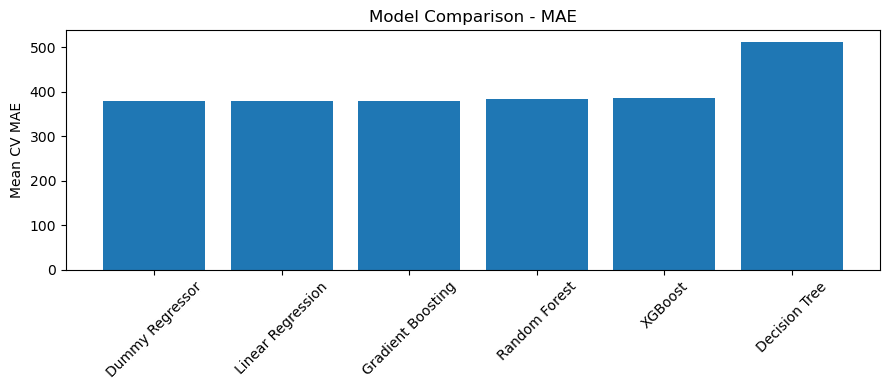

In [4]:
plt.figure(figsize=(9, 4))
plt.bar(results["Model"], results["Mean_CV_MAE"])
plt.title("Model Comparison - MAE")
plt.ylabel("Mean CV MAE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

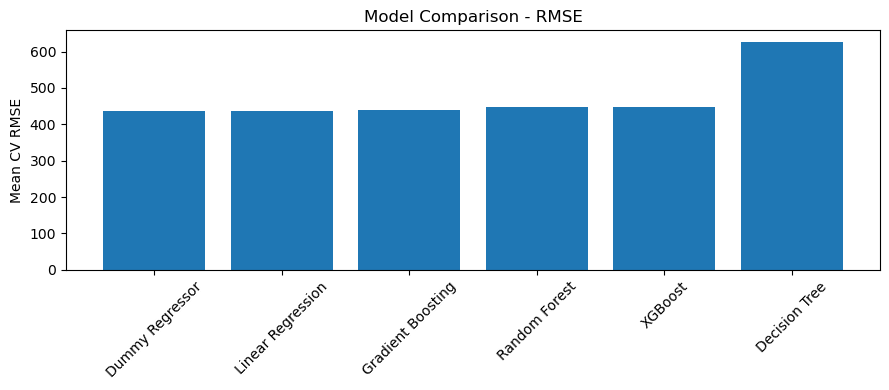

In [5]:
plt.figure(figsize=(9, 4))
plt.bar(results["Model"], results["Mean_CV_RMSE"])
plt.title("Model Comparison - RMSE")
plt.ylabel("Mean CV RMSE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
dummy = results[results["Model"] == "Dummy Regressor"]

if len(dummy) > 0:
    dummy_r2 = dummy.iloc[0]["Mean_CV_R2"]
    best_r2 = best_model["Mean_CV_R2"]

    print("Dummy Regressor R2:", round(dummy_r2, 4))
    print("Best candidate R2:", round(best_r2, 4))
    print("R2 improvement:", round(best_r2 - dummy_r2, 4))
else:
    print("Dummy Regressor was not found in the results.")

Dummy Regressor R2: -0.0004
Best candidate R2: -0.0004
R2 improvement: 0.0


In [7]:
os.makedirs("stage16_outputs", exist_ok=True)

results.to_csv(
    "stage16_outputs/regression_evaluation.csv",
    index=False
)

best_model.to_frame().T.to_csv(
    "stage16_outputs/best_regression_model.csv",
    index=False
)

print("Stage 16 results saved successfully.")

Stage 16 results saved successfully.


In [8]:
import pandas as pd

correlations = pd.read_csv(
    "stage14_outputs/yield_feature_correlations.csv"
)

display(correlations)

,Unnamed: 0,Correlation
0,rainfall,0.016959
1,Humidity_Rainfall,0.015530
2,Temperature_Rainfall,0.010961
3,NDVI_Rainfall,0.008303
4,soil_ph,0.007098
5,organic_matter,0.002207
6,sand_pct,-0.003933
7,OrganicMatter_Sand,-0.004481
8,NDVI_Temperature,-0.006547
9,Temperature_Humidity,-0.008135


In [9]:
import sqlite3
import pandas as pd

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

data = pd.read_sql_query(
    "SELECT * FROM agri_yield_train",
    conn
)

conn.close()

print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
display(data.head())

print("\nStatistical summary:")
display(data.describe().round(3))

Dataset shape: (10000, 9)

Column names:
['field_id', 'soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']

First 5 rows:


,field_id,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
0,F00001,6.25,2.66,41.6,25.2,70,110.2,0.46,4105.8
1,F00002,6.70,3.66,40.2,26.9,78,126.3,0.59,4247.8
2,F00003,7.21,3.45,40.0,27.6,66,109.4,0.64,4021.8
3,F00004,5.73,2.48,56.9,29.6,79,155.3,0.62,4326.8
4,F00005,6.88,3.61,30.6,25.0,80,172.6,0.62,3708.0



Statistical summary:


,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,6.509,2.748,44.958,26.994,74.523,140.034,0.575,4251.976
std,0.580,0.718,8.653,1.737,5.775,23.027,0.100,436.533
min,5.500,1.500,30.000,24.000,65.000,100.000,0.400,3500.200
25%,6.000,2.130,37.500,25.500,70.000,120.200,0.490,3868.050
50%,6.510,2.750,45.000,27.000,75.000,140.100,0.570,4257.150
75%,7.010,3.360,52.400,28.500,80.000,160.200,0.660,4638.325
max,7.500,4.000,60.000,30.000,84.000,180.000,0.750,5000.000


,Correlation
temperature,-0.0149
sand_pct,-0.0039
ndvi,-0.0016
humidity,0.0013
organic_matter,0.0022
soil_ph,0.0071
rainfall,0.0170


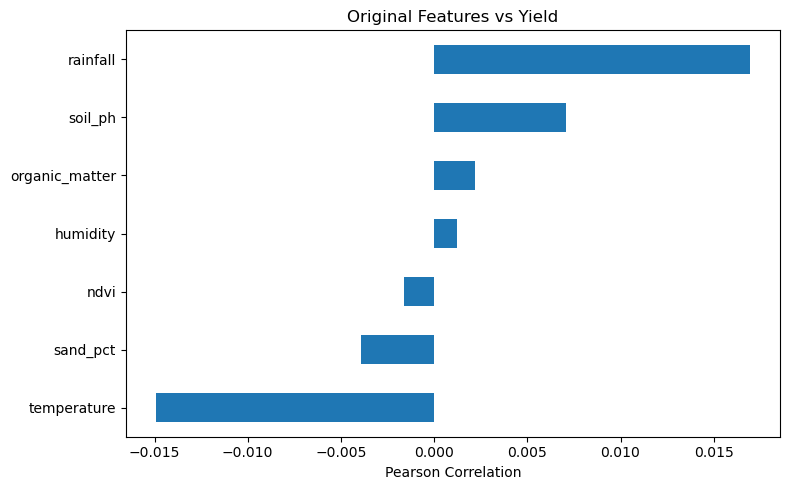

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

correlations = data.corr(numeric_only=True)["yield"]

correlations = correlations.drop("yield")
correlations = correlations.sort_values()

display(correlations.to_frame("Correlation").round(4))

correlations.plot(kind="barh", figsize=(8, 5))
plt.title("Original Features vs Yield")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

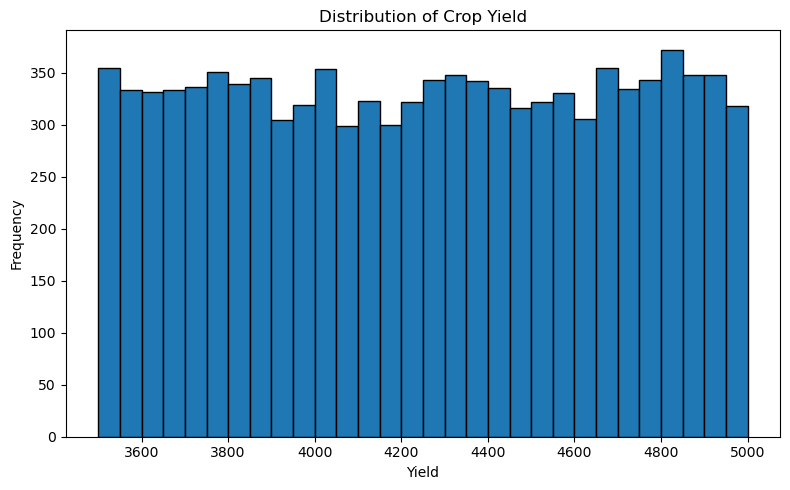

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(data["yield"], bins=30, edgecolor="black")

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

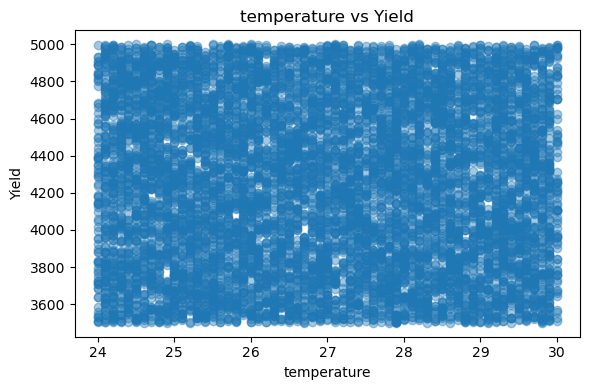

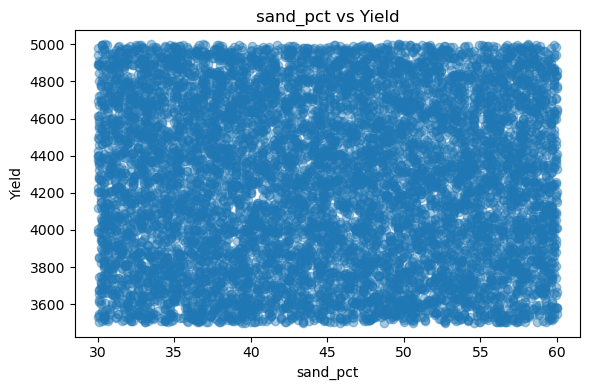

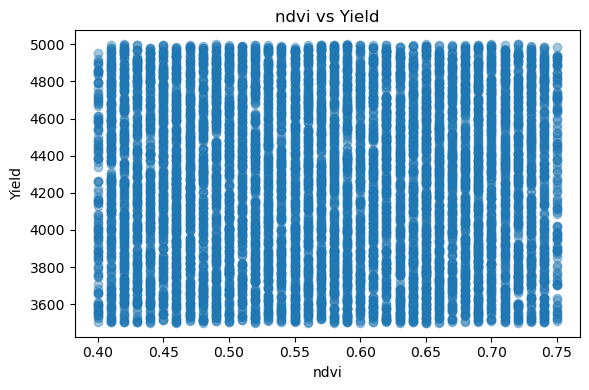

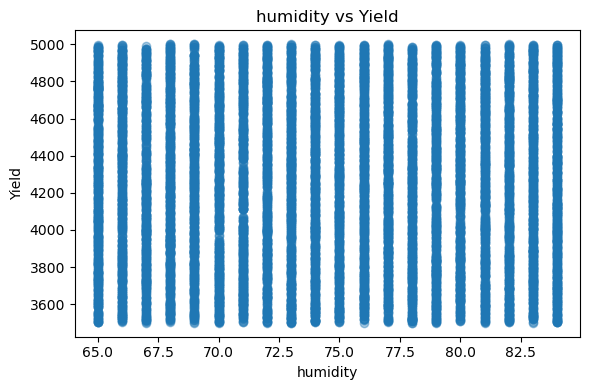

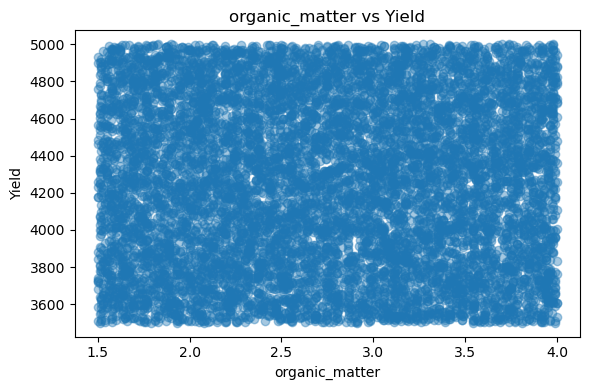

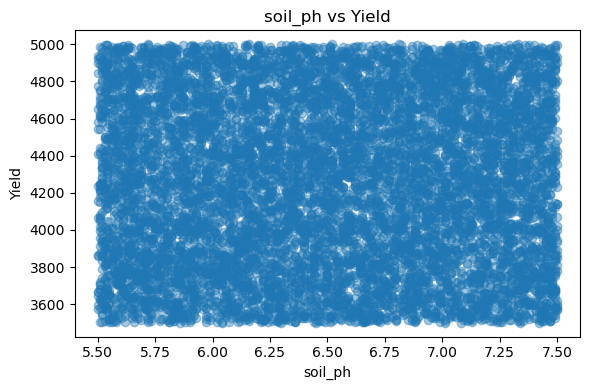

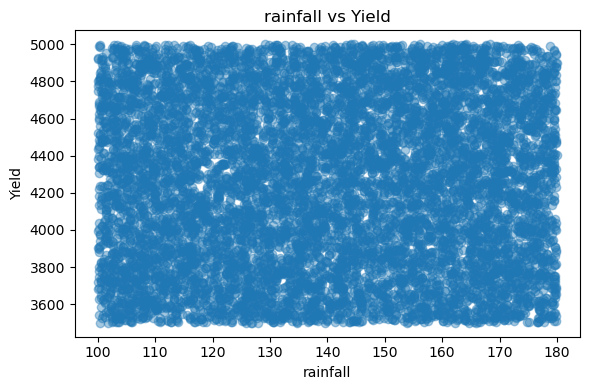

In [12]:
features = [
    "temperature",
    "sand_pct",
    "ndvi",
    "humidity",
    "organic_matter",
    "soil_ph",
    "rainfall"
]

for feature in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(data[feature], data["yield"], alpha=0.4)
    plt.xlabel(feature)
    plt.ylabel("Yield")
    plt.title(feature + " vs Yield")
    plt.tight_layout()
    plt.show()

In [13]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

X = data.drop(columns=["yield"])
y = data["yield"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

dummy = DummyRegressor(strategy="mean")
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

dummy_scores = cross_val_score(
    dummy, X, y, cv=cv, scoring="r2"
)

rf_scores = cross_val_score(
    rf, X, y, cv=cv, scoring="r2"
)

print("Dummy mean CV R2:", round(dummy_scores.mean(), 4))
print("Random Forest mean CV R2:", round(rf_scores.mean(), 4))
print("Random Forest fold scores:", rf_scores.round(4))

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ADMIN\AppData\Local\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ADMIN\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\ADMIN\AppData\Local\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py", line 359, in fit
    X, y = validate_data(
           ~~~~~~~~~~~~~^
        self,
        ^^^^^
    ...<5 lines>...
        ensure_all_finite=False,
        ^^^^^^^

In [14]:
print(data.columns.tolist())
print(data.dtypes)

['field_id', 'soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']
field_id           object
soil_ph           float64
organic_matter    float64
sand_pct          float64
temperature       float64
humidity            int64
rainfall          float64
ndvi              float64
yield             float64
dtype: object


In [15]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

X = data.drop(columns=["yield"])
X = X.select_dtypes(include="number")

y = data["yield"]

print("Features used:", X.columns.tolist())
print("Feature shape:", X.shape)

Features used: ['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']
Feature shape: (10000, 7)


In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

dummy = DummyRegressor(strategy="mean")

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

dummy_scores = cross_val_score(
    dummy, X, y, cv=cv, scoring="r2"
)

rf_scores = cross_val_score(
    rf, X, y, cv=cv, scoring="r2"
)

print("Dummy mean CV R2:", round(dummy_scores.mean(), 4))
print("Random Forest mean CV R2:", round(rf_scores.mean(), 4))
print("Random Forest fold scores:", rf_scores.round(4))

Dummy mean CV R2: -0.0004
Random Forest mean CV R2: -0.0447
Random Forest fold scores: [-0.057  -0.0387 -0.0401 -0.0447 -0.043 ]
